# **Importing Libraries**


In [1]:
#!pip install opencv-python numpy scikit-image scikit-learn xgboost joblib pandas lightgbm

In [1]:
# System and File Handling
import os
import time
from concurrent.futures import ThreadPoolExecutor

# Data Handling
import numpy as np
import pandas as pd

# Image Processing
import cv2
from skimage.feature import hog

# Machine Learning Models and Tools
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.neighbors import KNeighborsClassifier

# Joblib for Model Saving and Loading
import joblib

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns


# **Function to Count Dataset Files**

In [3]:
def count_dataset_files(dataset_path):
    total_count = 0
    class_counts = {}

    # Traverse the dataset directory
    for class_name in os.listdir(dataset_path):
        class_folder = os.path.join(dataset_path, class_name)
        if os.path.isdir(class_folder):  # Ensure it's a folder
            count = len([file for file in os.listdir(class_folder) if os.path.isfile(os.path.join(class_folder, file))])
            class_counts[class_name] = count
            total_count += count

    return total_count, class_counts

In [4]:
# Specify the path to your dataset
dataset_path = "datasett/train"
total_count, class_counts = count_dataset_files(dataset_path)

# Display results
print(f"Total number of files in the dataset: {total_count}")
print("Number of files per class:")
for class_name, count in class_counts.items():
    print(f"  {class_name}: {count}")

Total number of files in the dataset: 70295
Number of files per class:
  Apple___Apple_scab: 2016
  Apple___Black_rot: 1987
  Apple___Cedar_apple_rust: 1760
  Apple___healthy: 2008
  Blueberry___healthy: 1816
  Cherry_(including_sour)___healthy: 1826
  Cherry_(including_sour)___Powdery_mildew: 1683
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 1642
  Corn_(maize)___Common_rust_: 1907
  Corn_(maize)___healthy: 1859
  Corn_(maize)___Northern_Leaf_Blight: 1908
  Grape___Black_rot: 1888
  Grape___Esca_(Black_Measles): 1920
  Grape___healthy: 1692
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1722
  Orange___Haunglongbing_(Citrus_greening): 2010
  Peach___Bacterial_spot: 1838
  Peach___healthy: 1728
  Pepper_bell___Bacterial_spot: 1913
  Pepper_bell___healthy: 1988
  Potato___Early_blight: 1939
  Potato___healthy: 1824
  Potato___Late_blight: 1939
  Raspberry___healthy: 1781
  Soybean___healthy: 2022
  Squash___Powdery_mildew: 1736
  Strawberry___healthy: 1824
  Strawberry___Leaf_sc

# **Function to Load and Process Images**

In [6]:
# Function to load data and labels with parallelism
def process_single_image(file_path):
    img = cv2.imread(file_path, cv2.IMREAD_COLOR)
    img = cv2.resize(img, (64, 64))  # Resize to 64x64 for faster processing
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    features = hog(gray, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys')
    return features

def load_data_and_labels_parallel(dataset_path):
    images = []
    labels = []
    class_names = [folder for folder in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, folder))]

    with ThreadPoolExecutor() as executor:
        for label, class_name in enumerate(class_names):
            class_folder = os.path.join(dataset_path, class_name)
            file_paths = [os.path.join(class_folder, file) for file in os.listdir(class_folder) if os.path.isfile(os.path.join(class_folder, file))]
            results = executor.map(process_single_image, file_paths)
            images.extend(results)
            labels.extend([label] * len(file_paths))

    return np.array(images), np.array(labels), class_names


# **Load Dataset**

In [7]:
# Measure time for data loading
dataset_path = 'datasett/train'
start_time = time.time()
print("Loading data...")
X, y, class_names = load_data_and_labels_parallel(dataset_path)

end_time = time.time()
print(f"Data loaded in {end_time - start_time:.2f} seconds")


Loading data...
Data loaded in 394.35 seconds


# **Train-Test Split for the Dataset**

In [8]:
# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Dataset loaded. Number of classes: {len(class_names)}")


Dataset loaded. Number of classes: 38


# **Apply PCA for Dimensionality Reduction**

In [9]:
# Apply PCA to reduce dimensionality for faster training
print("Applying PCA for dimensionality reduction...")
pca = PCA(n_components=50)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print(f"PCA applied. Reduced dimensions: {X_train_pca.shape[1]}")


Applying PCA for dimensionality reduction...
PCA applied. Reduced dimensions: 50


# **Initialize and Train Models**

In [7]:
# Initialize models
models = {
    "SVM": SVC(probability=True, kernel='linear', random_state=42),
    "Random Forest": RandomForestClassifier(n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="mlogloss", nthread=-1, random_state=42),
    "LightGBM": LGBMClassifier(random_state=42, verbosity=-1),
}

In [17]:
# Train models and track accuracy
trained_models = {}
accuracies = {}
print("Training and evaluating models...\n")
for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train_pca, y_train)
    trained_models[model_name] = model
    
    print(f"Evaluating {model_name}...")
    y_pred = model.predict(X_test_pca)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred) * 100  # Convert to percentage
    accuracies[model_name] = accuracy
    print(f"Accuracy for {model_name}: {accuracy:.2f}%")

# Identify the best-performing model
best_model_name = max(accuracies, key=accuracies.get)
best_accuracy = accuracies[best_model_name]

print("\nBest Performing Model:")
print(f"{best_model_name} with Accuracy: {best_accuracy:.2f}%")


Training and evaluating models...

Training SVM...
Evaluating SVM...
Accuracy for SVM: 50.65%
Training Random Forest...
Evaluating Random Forest...
Accuracy for Random Forest: 55.74%
Training XGBoost...
Evaluating XGBoost...
Accuracy for XGBoost: 58.78%
Training LightGBM...
Evaluating LightGBM...
Accuracy for LightGBM: 57.94%

Best Performing Model:
XGBoost with Accuracy: 58.78%



Best Performing Model:
XGBoost with Accuracy: 58.78%

Classification Report for Best Model:
              precision    recall  f1-score   support

           0       0.34      0.36      0.35       419
           1       0.62      0.68      0.65       373
           2       0.53      0.42      0.47       345
           3       0.34      0.41      0.37       407
           4       0.49      0.43      0.46       366
           5       0.79      0.76      0.77       348
           6       0.72      0.72      0.72       330
           7       0.83      0.69      0.75       344
           8       0.87      0.86      0.87       374
           9       0.81      0.77      0.79       366
          10       0.72      0.80      0.76       384
          11       0.64      0.61      0.62       381
          12       0.68      0.67      0.67       380
          13       0.83      0.75      0.79       334
          14       0.75      0.74      0.75       342
          15       0.86      0.82      0.8

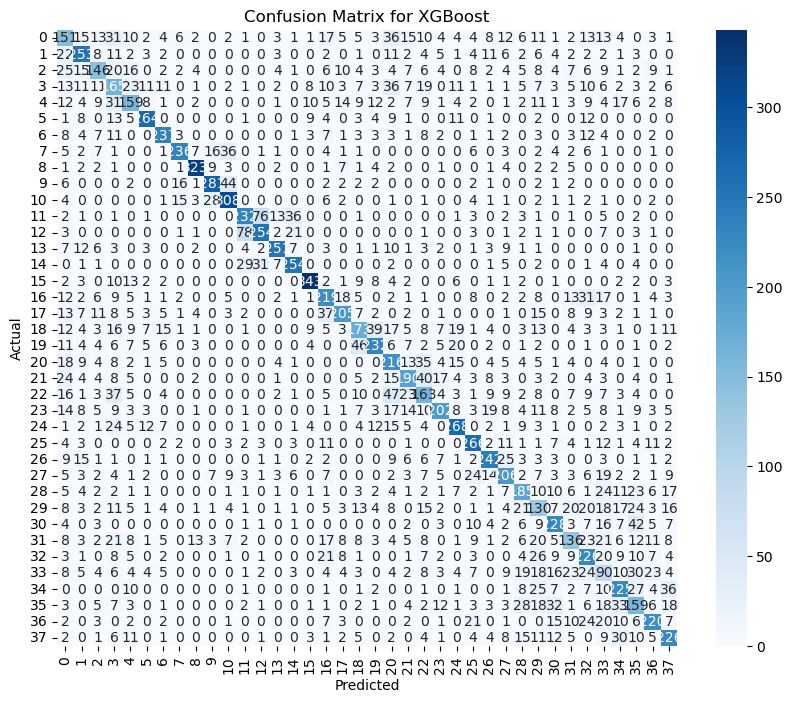

In [18]:
# Identify the best-performing model
best_model_name = max(accuracies, key=accuracies.get)
best_model = trained_models[best_model_name]
best_accuracy = accuracies[best_model_name]

# Print best model information
print("\nBest Performing Model:")
print(f"{best_model_name} with Accuracy: {best_accuracy:.2f}%")

# Predict using the best model
y_pred_best = best_model.predict(X_test_pca)

# Print classification report for the best model
print("\nClassification Report for Best Model:")
print(classification_report(y_test, y_pred_best))

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_best)
print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))
plt.title(f"Confusion Matrix for {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [19]:
# Save only the best model
best_model = trained_models[best_model_name]
joblib.dump(best_model, "model.pkl")
print(f"\nBest model '{best_model_name}' saved as 'model.pkl'.")


Best model 'XGBoost' saved as 'model.pkl'.


In [20]:
# Save PCA transformer
joblib.dump(pca, 'pca_transformer.pkl')

['pca_transformer.pkl']

# **Function to Test a Single Image**

In [21]:
# Test a single image
def test_single_image(image_path, model_path, pca_path):
    # Load the trained model and PCA transformer
    model = joblib.load(model_path)
    pca = joblib.load(pca_path)

    # Preprocess the input image
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    img = cv2.resize(img, (64, 64))  # Resize to the same dimensions used during training
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    features = hog(gray, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys')

    # Transform the features using PCA
    features_pca = pca.transform([features])

    # Predict the class
    prediction = model.predict(features_pca)

    # Output the result
    return prediction

# Test with a sample image
test_image_path = "1ac53f1b-5d2c-4f6a-b4fe-dccd5dad551f___FAM_B.Rot 3046_flipLR.JPG"  # Update with the actual path to a test image
model_path = "model.pkl"  # Update with the desired model's file path
pca_path = "pca_transformer.pkl"

# Perform testing
predicted_label = test_single_image(test_image_path, model_path, pca_path)
print(f"Predicted Class: {class_names[predicted_label[0]]}")


Predicted Class: Grape___Black_rot
